# Quantum Metal circuit examples A–E — every single-component and sub-circuit example on one test chip (Quantcore PDK rebuild)

**What the chip is.** Not a chip in the source: the 19 Qiskit Metal circuit-example notebooks
`docs/circuit-examples/{A.Qubits, B.Resonators, C.Composite-bi-partite, D.Qubit-couplers, E.Input-output-coupling}/*.ipynb`
(© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/component_examples.md`) each draw one component or a small sub-circuit. Here they are gathered on
one **catalogue board** as component tests for the `metal:` wrappers and their LOM models: each example on its own
7 × 7 mm tile of a 35 × 28 mm chip, with its Metal origin at the tile centre (instance names get the tile prefix, e.g.
`D31_Q1`). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds them with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): every
Metal component is drawn through the `metal:<Class>` wrapper with the options its notebook set; the board, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal examples | Quantcore PDK rebuild |
|---|---|---|
| chip | one `DesignPlanar` per notebook, centred on (0, 0) | one 35 × 28 mm board of 7 × 7 mm tiles (it does not fit the 7.5 mm die), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | E.41 / E.42 drive their own qubit / meander | kept **inside their tiles**: the pad rule is not applied to this catalogue board (step 4); the two `pad_edge` design warnings stay |
| junctions | Metal junction lines (10 nH assumed) | Quantcore trilayer junctions: PDK nominal, PDK SQUIDs on the flux-tunable cells, the interdigitated transmon sized for 4.05 GHz; the A.08 / A.09 junction tiles keep Metal's own drawing (2/0 only, a reference) |
| cheese | none (no example exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteMeander` / `RouteStraight` | qcc `cpw` routes on Metal's corner points (fixed-length meanders where needed), 10 / 6 µm |
| placement | each example at its origin | the tile grid centred in the die |

**Reproduced exactly:** step 1 runs each example notebook's own code in a headless Metal design (GUI calls become
no-ops; analysis / render / export lines are skipped) and reads back the final design: every component with its
options as the notebook set them (the differences from Metal's template are passed to `metal:<Class>`), its position
and orientation, and every route's end pins, Metal corner points, fillet and length. `RouteMeander`s run on Metal's
corner points (into an `OpenToGround`: a plain CPW on that path; between two pads: a fixed-length meander, Metal's
length + 0.05 µm, which keeps the router on Metal's path); `RouteStraight` is a straight qcc CPW.

**Not reproduced:** the analysis cells (Q3D / HFSS / LOM / EPR in some notebooks need Ansys) and screenshots. The two
junction notebooks (A.08 `jj_dolan`, A.09 `jj_manhattan`) draw a junction on its own, with no pins and no circuit
element. B.11's meander runs between two `OpenToGround`s (a λ/2 on its own).

The notebook goes step by step: the source examples → PDK → board → pads → components → routes → centring → DRC →
netlist → LOM → FEM jobs → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
import contextlib, glob, io, json, logging, re, warnings
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.metal.geometry import template_options, PLACEMENT_OPTIONS
SRC = upstream_path("qiskit-metal", "docs/circuit-examples").as_posix() + "/"  # third_party/ or other-libs/

**The source examples.** The cell below runs each of the 19 example notebooks in a headless Metal design and
reads back every component (class, position, orientation, the options that differ from Metal's template) and every
route (end pins, corner points, fillet, length). It prints one line per tile. (About half a minute.)

In [3]:
# run every example notebook's code in a headless Metal design and read back its final design
os.environ["QISKIT_METAL_HEADLESS"] = "True"
logging.disable(logging.CRITICAL); warnings.simplefilter("ignore")
import qiskit_metal
from qiskit_metal import Dict, designs
SKIP = re.compile(r"screenshot|savefig|display\(|Image\(|Analysis\(|\.sim\.|renderers|export_to|run_lom|run_epr|"
                  r"plot|qm\.view|metal\.view|\.close\(\)|pip install|^%|^!|get_convergence|setup\.|\.run\(")


class NoGui:                                     # stands in for MetalGUI: every call is a no-op
    def __getattr__(self, name): return NoGui()
    def __call__(self, *a, **k): return NoGui()


def plain(v):
    if isinstance(v, dict): return {k: plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)): return [plain(x) for x in v]
    return float(v) if hasattr(v, "dtype") else v


EX = {}
for path in sorted(glob.glob(SRC + "[A-E].*/*.ipynb")):
    group, stem = Path(path).parent.name[0], Path(path).stem  # (Windows glob returns "\\" separators)
    tile = group + stem[:2]                      # e.g. A01, B11, D31
    g = {"NoGui": NoGui, "metal": qiskit_metal, "qm": qiskit_metal, "designs": designs, "Dict": Dict}
    for cell in json.load(open(path, encoding="utf-8"))["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "\n".join(l for l in "".join(cell["source"]).splitlines() if not SKIP.search(l.strip()))
        src = re.sub(r"(MetalGUI|metal\.gui|qm\.gui)\(design\)", "NoGui()", src)
        src = src.replace(", MetalGUI", "").replace("MetalGUI, ", "")
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(src, g)
        except Exception:                        # e.g. an optional GUI import; the design is read below
            pass
    design = g["design"]
    design.rebuild()
    comps, routes = {}, {}
    for name, c in design.components.items():
        cls, p = type(c).__name__, c.parse_options()
        if "pin_inputs" in c.options:            # a Metal route
            pi = c.options.pin_inputs
            routes[name] = dict(cls=cls, ends=(pi.start_pin.component, pi.start_pin.pin, pi.end_pin.component,
                                                pi.end_pin.pin),
                                pts=[(1000 * float(x), 1000 * float(y)) for x, y in c.get_points()],
                                fillet=1000 * float(p.fillet))
            routes[name]["length"] = (1000 * float(p.total_length) if cls == "RouteMeander" else  # straight: as drawn
                                      sum(math.dist(a, b) for a, b in zip(routes[name]["pts"], routes[name]["pts"][1:])))
        else:
            tmpl = template_options(cls)
            comps[name] = dict(cls=cls, at=(1000 * float(p.pos_x), 1000 * float(p.pos_y)), rot=float(p.orientation),
                               pins=list(c.pins),
                               opts={k: plain(v) for k, v in c.options.items()
                                     if k not in PLACEMENT_OPTIONS and k != "chip" and plain(v) != tmpl.get(k)})
    EX[tile] = dict(title=stem[3:].replace("_", " "), comps=comps, routes=routes)
logging.disable(logging.NOTSET)
for tile, ex in EX.items():
    print(tile, ex["title"], "|", ", ".join(f"{n} ({c['cls']})" for n, c in ex["comps"].items()),
          "|", ", ".join(f"{n} ({r['cls']}, {r['length']:.0f} µm)" for n, r in ex["routes"].items()))

A01 Transmon cross | Q1 (TransmonCross) | 
A02 Transmon floating | Q1 (TransmonPocket) | 
A03 concentric transmon | qubit1 (TransmonConcentric) | 
A04 Interdigitated Transmon | qubit1 (TransmonInterdigitated) | 
A05 Transmon cross fl | Q1 (TransmonCrossFL) | 
A06 Transmon floating 6 | Q1 (TransmonPocket6) | 
A07 Transmon floating cl | Q1 (TransmonPocketCL) | 
A08 JJ-Dolan | JJ2 (jj_dolan) | 
A09 JJ-Manhattan | JJ2 (jj_manhattan) | 
A10 Transmon floating teeth | Q1 (TransmonPocketTeeth) | 
A11 Star shaped qubit | Star (StarQubit) | 
B11 Resonator Meander | Open_meander_start (OpenToGround), Open_meander_end (OpenToGround) | meanderTest (RouteMeander, 9000 µm)
C21 OneTransmonsWithMeanderAndOTG | Q1 (TransmonPocket), open_to_ground (OpenToGround) | coupler (RouteMeander, 5000 µm)
D31 TwoCrossmonsTunableCoupler | Q1 (TransmonCrossFL), Q2 (TransmonCrossFL), Tune_C_Q12 (TunableCoupler01) | 
D32 TwoTransmonsDirectCoupling | Q1 (TransmonPocket), Q2 (TransmonPocket) | coupler (RouteStraight, 15

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this board that means: the 35 × 28 mm box gets the QCT frame; every qubit gets a trilayer junction (nominal, a SQUID on the flux-tunable cells, sized for the interdigitated transmon); the free ground gets the PDK cheese band; the launchpads of the E tiles stay in their tiles (step 4).

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The board and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
board is a 5 × 4 grid of 7 mm tiles, filled left to right and top to bottom in the examples' order (A01 … A11, B11,
C21, D31 … D33, E41 … E43); `CENTRE[tile]` is each tile's centre, where its Metal origin goes.

{'A01': (3500.0, 24500.0), 'A02': (10500.0, 24500.0), 'A03': (17500.0, 24500.0), 'A04': (24500.0, 24500.0), 'A05': (31500.0, 24500.0), 'A06': (3500.0, 17500.0), 'A07': (10500.0, 17500.0), 'A08': (17500.0, 17500.0), 'A09': (24500.0, 17500.0), 'A10': (31500.0, 17500.0), 'A11': (3500.0, 10500.0), 'B11': (10500.0, 10500.0), 'C21': (17500.0, 10500.0), 'D31': (24500.0, 10500.0), 'D32': (31500.0, 10500.0), 'D33': (3500.0, 3500.0), 'E41': (10500.0, 3500.0), 'E42': (17500.0, 3500.0), 'E43': (24500.0, 3500.0)}


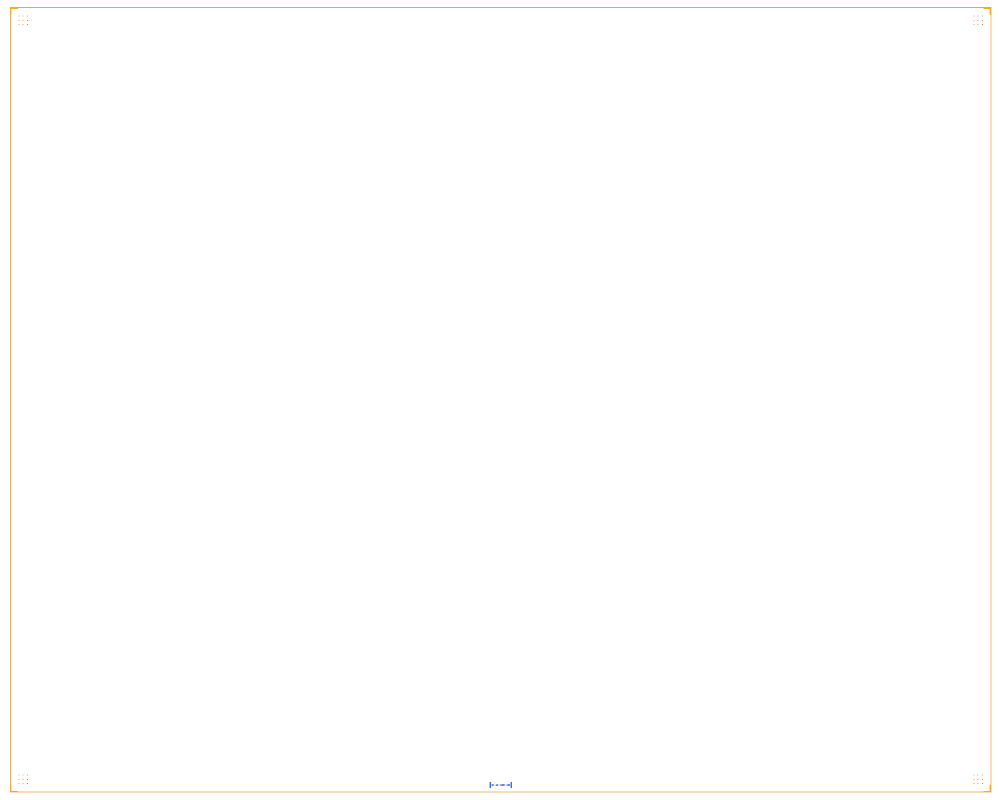

WindowsPath('examples/designs/metal/component_examples_step_die.png')

In [5]:
PITCH, NCOL, NROW = 7000, 5, 4
d = Designer("component_examples", box=(0, 0, NCOL * PITCH, NROW * PITCH), chip={"name_chip": "MetalExamples"},
             live=LIVE)
CENTRE = {tile: ((k % NCOL + 0.5) * PITCH, (NROW - k // NCOL - 0.5) * PITCH) for k, tile in enumerate(EX)}
print({t: c for t, c in CENTRE.items()})
rebuild(d)
snap(d, OUT / "component_examples_step_die.png", size=(1000, 800), width=400)

## 4 · Pads: why the pad rule is not applied here

The PDK puts the outer etch of every bond pad **100 µm from the die edge** (`frame.pad_edge`). This board is a catalogue of component
examples, not a chip with I/O: its only launchpads are the two `LaunchpadWirebond`s of tiles **E.41** and **E.42**,
which drive the tile's own qubit (E.41) or open meander (E.42) over a few hundred µm. Sliding them to the board edge
(≈ 6 mm away, through other tiles) would break the examples they belong to, so they stay where their notebooks put
them, and the DRC keeps its two `pad_edge` design warnings for them (flagged, as the PDK asks, not enforced). They are
placed with their tiles in step 5.

In [6]:
LAUNCHPADS = [(t, n, c["cls"], c["at"]) for t, ex in EX.items() for n, c in ex["comps"].items()
              if c["cls"].startswith("Launchpad")]
print("launchpads in the examples (tile, name, class, Metal position µm):", LAUNCHPADS)

launchpads in the examples (tile, name, class, Metal position µm): [('E41', 'P4_Q', 'LaunchpadWirebondCoupled', (990.0, 2812.0000000000005)), ('E42', 'P4_Q', 'LaunchpadWirebondCoupled', (990.0, 2812.0000000000005))]


## 5 · Components: every example's cells, with PDK junctions

Each tile gets its example's components at their Metal positions (plus the tile centre), with the notebook's options.
**Junctions:** every qubit class gets a Quantcore trilayer junction (`trilayer_junction`): the PDK nominal one (0.5 ×
0.6 µm fingers → R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); the flux-tunable cells (`TransmonCrossFL`, `TunableCoupler01`)
a PDK SQUID (two 0.25 × 0.6 µm junctions, 45 kΩ in parallel); the interdigitated transmon (C_Σ ≈ 216 fF without the
junction, this design's LOM before the rebuild) is **sized for 4.05 GHz** (L_J ≈ 6.4 nH, R_n ≈ 43 kΩ) to stay in
the 4–8 GHz band (nominal: ≈ 3.95 GHz). `junction=` carries L_J / C_J to the LOM.

**Free pins:** Metal draws a pin with no route as an open end, so each component's unrouted pins are passed as
`open_pins` (the wrapper then draws them open, as Metal does).

**Claws vs arms (PDK `pdk_claw`):** a `TransmonCross` claw longer than the arm reach (arm + ground spacing − half the
arm width = 195 µm with Metal's 200 µm default arm) runs into the side arms' gap; the fix is a longer
`cross_length`. Here: 30 µm claws (A.01, A.05) and D.31's 95 µm bus claws, all inside the reach (zoom in step 15).

26 components; junctions: {'junction': {'Lj_nH': 6.7344, 'Cj_fF': 15.0}, 'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} | interdigitated L_J 6.399 nH


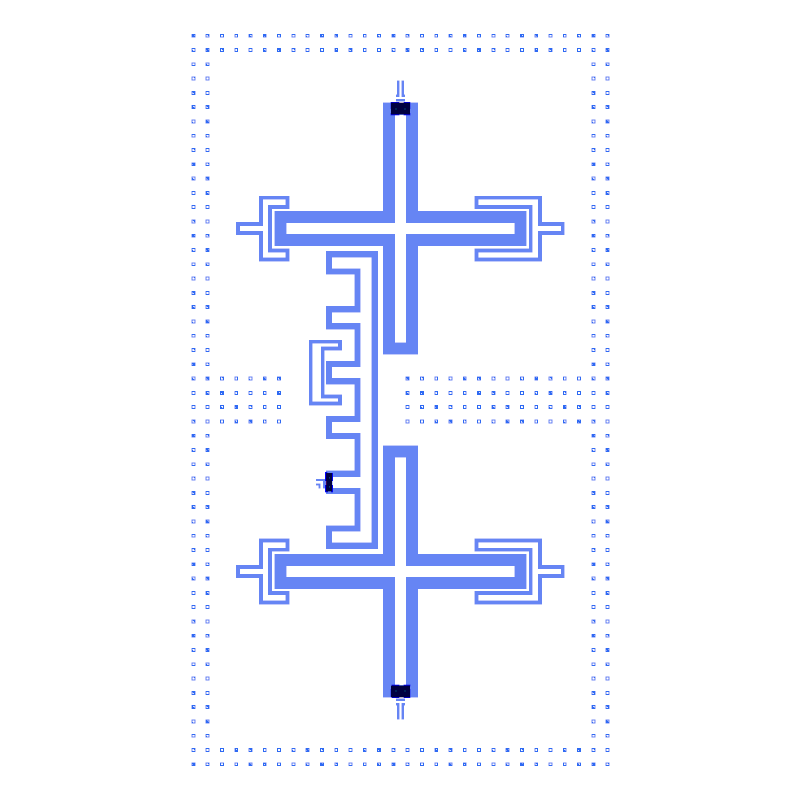

WindowsPath('examples/designs/metal/component_examples_step_parts.png')

In [7]:
# Quantcore trilayer junctions on the PDK rule (Nb Δ 1.4 meV): every qubit the PDK nominal junction (0.5 × 0.6 µm →
# R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); flux-tunable cells a Quantcore SQUID (R_n 45 kΩ in parallel); the
# interdigitated transmon (C_Σ ≈ 216 fF without the junction, this design's LOM before the rebuild) is sized for
# 4.05 GHz to stay inside the PDK's 4–8 GHz band (nominal: ≈ 3.95 GHz)
SQUIDS = {"TransmonCrossFL", "TunableCoupler01"}
LJ_PDK = trilayer_junction("metal:TransmonPocket")[1]["Lj_nH"]
LJ_FOR = {"TransmonInterdigitated": size_junction(4.05, 215.9, c_includes_junction=False).lj_nH}


def pdk_junction(cls):
    """``d.add`` keywords for a qubit class: ``junction_type`` (+ sizing) and the drawn junction's ``junction``."""
    squid = cls in SQUIDS
    params, junction = trilayer_junction(f"metal:{cls}", lj_nH=LJ_FOR.get(cls, LJ_PDK if squid else None), squid=squid)
    return dict(junction=junction, **params)


QUBITS = {"TransmonCross", "TransmonCrossFL", "TransmonPocket", "TransmonPocket6", "TransmonPocketCL",
          "TransmonPocketTeeth", "TransmonConcentric", "TransmonInterdigitated", "StarQubit", "TunableCoupler01"}
H = {}                                           # tile → {Metal name: handle}
with d.batch():
    for tile, ex in EX.items():
        cx, cy = CENTRE[tile]
        used = {(r["ends"][0], r["ends"][1]) for r in ex["routes"].values()} | \
               {(r["ends"][2], r["ends"][3]) for r in ex["routes"].values()}
        H[tile] = {}
        for n, c in ex["comps"].items():
            kw = pdk_junction(c["cls"]) if c["cls"] in QUBITS else {}
            free = [p for p in c["pins"] if (n, p) not in used]
            if free and c["cls"] != "OpenToGround":   # Metal draws a pin with no route as an open end
                kw["open_pins"] = ",".join(free)
            H[tile][n] = d.add(f"{tile}_{n}", f"metal:{c['cls']}", at=(cx + c["at"][0], cy + c["at"][1]), rot=c["rot"],
                               **kw, **c["opts"])
print(len(d.data["instances"]), "components;", "junctions:",
      {k: v for k, v in pdk_junction("TransmonCrossFL").items()}, "| interdigitated L_J",
      round(LJ_FOR["TransmonInterdigitated"], 3), "nH")
cx, cy = CENTRE["D31"]
snap(d, OUT / "component_examples_step_parts.png", box=(cx - 700, cy - 700, cx + 700, cy + 700), size=(800, 800),
     width=320)

## 6 · Routes and sim groups

Each example's routes on Metal's own corner points (`nodes`), 10 / 6 µm CPW, with Metal's fillet as the turn radius:
- a `RouteMeander` into an `OpenToGround`: a plain CPW on Metal's exact path (the LOM sees it as drawn);
- a `RouteMeander` between two pads: a fixed-length meander (Metal's length + 0.05 µm keeps the router on Metal's
  path);
- if a Metal segment is shorter than two fillets (Metal then skips that fillet; the qcc router does not), the qcc
  meander picks its own footprint at Metal's length (B.11, E.42: printed);
- a `RouteStraight`: a straight qcc CPW.

**Sim groups** (FEM boxes): A.01 (TransmonCross) and A.02 (TransmonPocket) alone, D.31 (two crossmons with the tunable
coupler; Q3D C-matrix each) and C.21 (a pocket qubit with its open meander; eigenmode).

B11_meanderTest: a Metal segment is shorter than its 99.99 µm fillet: qcc meander footprint
E42_bus: a Metal segment is shorter than its 90.00 µm fillet: qcc meander footprint


{'B11_meanderTest': 9000.0, 'C21_coupler': 5000.0, 'D32_coupler': 150.0, 'D33_coupler': 5000.0, 'E42_bus': 10000.0} (Metal: {'B11_meanderTest': 9000, 'C21_coupler': 5000, 'D32_coupler': 150, 'D33_coupler': 5000, 'E42_bus': 10000} )


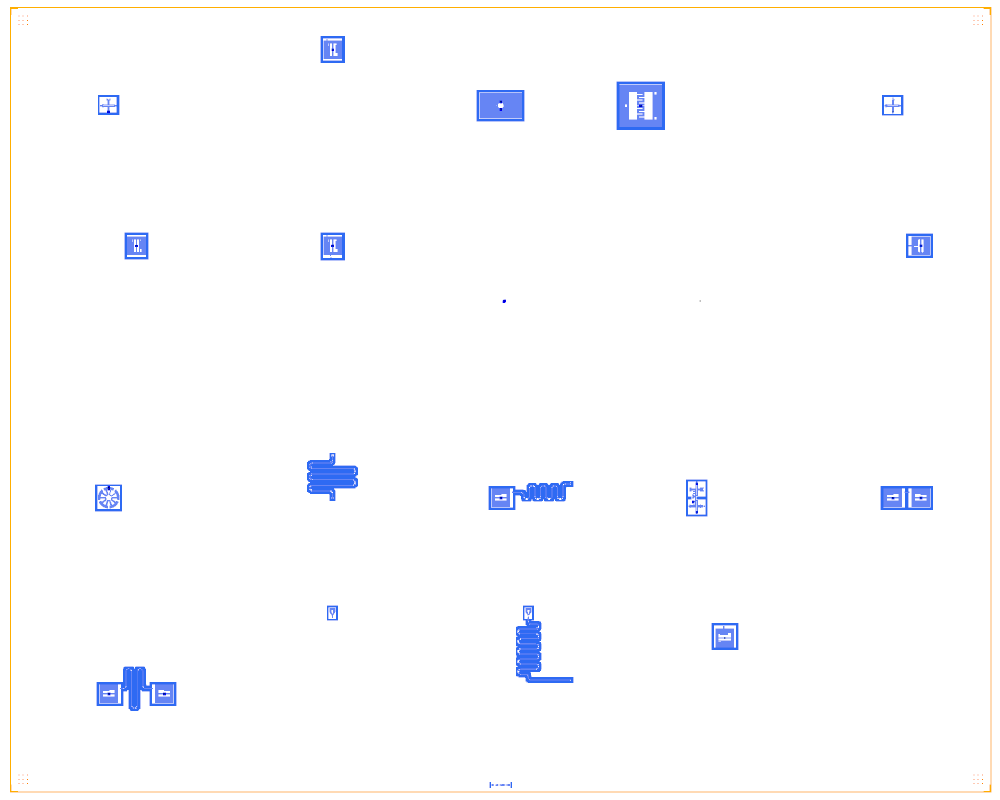

WindowsPath('examples/designs/metal/component_examples_step_routes.png')

In [8]:
def fits(pts, r):  # every segment of Metal's polyline takes two qcc fillets of radius r (the router's rule)
    return all(math.dist(a, b) >= 2 * r - 1e-6 for a, b in zip(pts, pts[1:]))


with d.batch():
    for tile, ex in EX.items():
        cx, cy = CENTRE[tile]
        h = H[tile]
        for n, r in ex["routes"].items():
            q0, p0, q1, p1 = r["ends"]
            otg = "OpenToGround" in (ex["comps"][q0]["cls"], ex["comps"][q1]["cls"])
            meander = r["cls"] == "RouteMeander"
            nodes = [(cx + x, cy + y) for x, y in r["pts"][1:-1]] if meander else []
            if meander and not fits(r["pts"], r["fillet"]):
                print(f"{tile}_{n}: a Metal segment is shorter than its {r['fillet']:.2f} µm fillet: qcc meander footprint")
                nodes, extra = [], dict(meander=r["length"])
            elif meander and not otg:
                extra = dict(meander=r["length"] + 0.05)
            else:
                extra = {}
            d.route(f"{tile}_{n}", getattr(h[q0], p0), getattr(h[q1], p1), r=r["fillet"] or 1, a=10, b=6,
                    nodes=nodes, **extra)
# FEM: a few tiles (qubit alone, coupler pair, qubit + meander)
d.sim_group("A01", ["A01_Q1"], margin_um=200, analyses=["q3d_cmatrix"])
d.sim_group("A02", ["A02_Q1"], margin_um=200, analyses=["q3d_cmatrix"])
d.sim_group("D31", ["D31_Q1", "D31_Q2", "D31_Tune_C_Q12"], margin_um=100, analyses=["q3d_cmatrix"])
d.sim_group("C21", ["C21_Q1", "C21_coupler", "C21_open_to_ground"], margin_um=200, analyses=["eigenmode_epr"])
rebuild(d)
L = d.result.route_lengths()
print({k: round(v, 1) for k, v in L.items()}, "(Metal:", {f"{t}_{n}": round(r["length"]) for t, e in EX.items()
                                                          for n, r in e["routes"].items()}, ")")
snap(d, OUT / "component_examples_step_routes.png", size=(1000, 800), width=400)

## 7 · Centre the content and save

The PDK wants the content centred in the die. The tiles are filled from the top left and the last row has only four
tiles (and the examples are not centred on their Metal origins), so the content leans up and right. `center_in_die`
shifts every component and route waypoint so the content's centre is the board's centre; the tile centres move with
it (`CENTRE`, used by the snapshots). Then the design is saved: the JSON is the deliverable.

In [9]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
CENTRE = {t: (x + shift[0], y + shift[1]) for t, (x, y) in CENTRE.items()}
DESIGN = d.save(OUT / "component_examples.json")
print(d, "→", DESIGN)

content shifted by (-478.5, -935.6) µm
<Designer component_examples: 26 instances, 5 routes, live=False> → examples\designs\metal\component_examples.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**. The `dangling_port` warnings are every pin the examples leave free (drawn open,
`open_pins`, as Metal draws a pin with no route) and the junction attachment points `squid_a` / `squid_b`. The two
`overlap` warnings are D.31's coupler bounding box over both crossmons, as in the source (it sits between their arms;
the metal does not touch). **PDK design warnings:** two `pad_edge` (the E.41 / E.42 launchpads, kept in their tiles:
step 4). No `pdk_rn`: the nominal junctions are 45 kΩ, each PDK SQUID (A.05, D.31's two crossmons and coupler; two
90 kΩ junctions) is 45 kΩ in parallel, and the interdigitated transmon's sized junction is ≈ 43 kΩ. No `pdk_claw`:
every claw is inside its arm's reach. The A.08 / A.09 tiles are listed as junction type `Metal` (Metal's own
drawing, kept as a reference).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [10]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 80 warnings · 2 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 78 | A01_Q1.a is not connected (no route or snap) |
| warning | `overlap` | 2 | D31_Q1 and D31_Tune_C_Q12 overlap |
| PDK design warning | `pad_edge` | 2 | E41_P4_Q: outer edge 5276 µm from the die edge; the Quantcore PDK puts pads 100 µm from it — place it with edg… |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -0) µm |
| junction types | Quantcore Junction × 14, Quantcore Squid × 4, Metal × 2 |
| PDK design warnings | 2 (pad_edge × 2) |
| pad_edge | E41_P4_Q: outer edge 5276 µm from the die edge; the Quantcore PDK puts pads 100 µm from it — place it with edge='auto' |
| pad_edge | E42_P4_Q: outer edge 5276 µm from the die edge; the Quantcore PDK puts pads 100 µm from it — place it with edge='auto' |

## 9 · Netlist and LOM

Every `metal:` cell goes through its LOM model (the per-component table is `lom/metal_models.py`); routes between two
capacitive ends or between a pad and an `OpenToGround` are λ/2 `TLres`. The whole board (71 nodes) is one netlist;
the tiles are independent sub-circuits of it.

In [11]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("A01_Q1.", "C21_"))})

**72 nodes · 164 branches · 0 controls · 34 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `A01_Q1` | `A01_Q1.island` |
| `A01_Q1.a` | `A01_Q1.a` |
| `A01_Q1.b` | `A01_Q1.b` |
| `A01_Q1.c` | `A01_Q1.c` |
| `A02_Q1.island1` | `A02_Q1.island1` |
| `A02_Q1.island2` | `A02_Q1.island2` |
| `A02_Q1.a` | `A02_Q1.a` |
| `A02_Q1.b` | `A02_Q1.b` |
| `A02_Q1.c` | `A02_Q1.c` |
| `A03_qubit1.island1` | `A03_qubit1.island1` |
| `A03_qubit1.island2` | `A03_qubit1.island2` |
| `A03_qubit1.pin1` | `A03_qubit1.pin1` |
| `A04_qubit1.island1` | `A04_qubit1.island1` |
| `A04_qubit1.island2` | `A04_qubit1.island2` |
| `A04_qubit1.readout` | `A04_qubit1.readout` |
| `A04_qubit1.bus1` | `A04_qubit1.bus1` |
| `A04_qubit1.bus2` | `A04_qubit1.bus2` |
| `A05_Q1` | `A05_Q1.island` |
| `A05_Q1.a` | `A05_Q1.a` |
| `A05_Q1.b` | `A05_Q1.b` |
| `A05_Q1.c` | `A05_Q1.c` |
| `A06_Q1.island1` | `A06_Q1.island1` |
| `A06_Q1.island2` | `A06_Q1.island2` |
| `A06_Q1.a` | `A06_Q1.a` |
| `A06_Q1.b` | `A06_Q1.b` |
| `A06_Q1.c` | `A06_Q1.c` |
| `A07_Q1.island1` | `A07_Q1.island1` |
| `A07_Q1.island2` | `A07_Q1.island2` |
| `A07_Q1.a` | `A07_Q1.a` |
| `A07_Q1.b` | `A07_Q1.b` |
| `A07_Q1.c` | `A07_Q1.c` |
| `A10_Q1.island1` | `A10_Q1.island1` |
| `A10_Q1.island2` | `A10_Q1.island2` |
| `A10_Q1.readout` | `A10_Q1.readout` |
| `A11_Star` | `A11_Star.island` |
| `A11_Star.pin_cpl1` | `A11_Star.pin_cpl1` |
| `A11_Star.pin_cpl2` | `A11_Star.pin_cpl2` |
| `A11_Star.pin_cpl3` | `A11_Star.pin_cpl3` |
| `A11_Star.pin_cpl4` | `A11_Star.pin_cpl4` |
| `A11_Star.pin_rdout` | `A11_Star.pin_rdout` |
| `B11_Open_meander_start.end` | `B11_Open_meander_start.end`, `B11_Open_meander_end.end` |
| `C21_Q1.island1` | `C21_Q1.island1` |
| `C21_Q1.island2` | `C21_Q1.island2` |
| `C21_Q1.readout` | `C21_Q1.readout`, `C21_open_to_ground.end` |
| `D31_Q1` | `D31_Q1.island` |
| `D31_Q1.bus_01` | `D31_Q1.bus_01` |
| `D31_Q1.readout` | `D31_Q1.readout` |
| `D31_Q2` | `D31_Q2.island` |
| `D31_Q2.bus_02` | `D31_Q2.bus_02` |
| `D31_Q2.readout` | `D31_Q2.readout` |
| `D31_Tune_C_Q12` | `D31_Tune_C_Q12.island` |
| `D31_Tune_C_Q12.Control` | `D31_Tune_C_Q12.Control` |
| `D32_Q1.island1` | `D32_Q1.island1` |
| `D32_Q1.island2` | `D32_Q1.island2` |
| `D32_Q1.readout` | `D32_Q1.readout`, `D32_Q2.readout` |
| `D32_Q2.island1` | `D32_Q2.island1` |
| `D32_Q2.island2` | `D32_Q2.island2` |
| `D33_Q1.island1` | `D33_Q1.island1` |
| `D33_Q1.island2` | `D33_Q1.island2` |
| `D33_Q1.readout` | `D33_Q1.readout`, `D33_Q2.readout` |
| `D33_Q2.island1` | `D33_Q2.island1` |
| `D33_Q2.island2` | `D33_Q2.island2` |
| `E41_P4_Q.pad` | `E41_P4_Q.pad` |
| `E41_P4_Q.tie` | `E41_P4_Q.tie` |
| `E42_P4_Q.pad` | `E42_P4_Q.pad` |
| `E42_P4_Q.tie` | `E42_P4_Q.tie`, `E42_open_to_ground.end` |
| `E43_Q1.island1` | `E43_Q1.island1` |
| `E43_Q1.island2` | `E43_Q1.island2` |
| `E43_Q1.a` | `E43_Q1.a` |
| `E43_Q1.b` | `E43_Q1.b` |
| `E43_Q1.c` | `E43_Q1.c` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_A01_Q1` | C | `A01_Q1` – `gnd` | 86.9 fF |
| `J_A01_Q1` | JJ | `A01_Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A01_Q1_a` | C | `A01_Q1` – `A01_Q1.a` | 1.1 fF |
| `Cc_A01_Q1_a` | C | `A01_Q1.a` – `gnd` | 29.8 fF |
| `Cg_A01_Q1_b` | C | `A01_Q1` – `A01_Q1.b` | 1.1 fF |
| `Cc_A01_Q1_b` | C | `A01_Q1.b` – `gnd` | 29.8 fF |
| `Cg_A01_Q1_c` | C | `A01_Q1` – `A01_Q1.c` | 0.095 fF |
| `Cc_A01_Q1_c` | C | `A01_Q1.c` – `gnd` | 11.8 fF |
| `C_A02_Q1_1` | C | `A02_Q1.island1` – `gnd` | 36 fF |
| `C_A02_Q1_2` | C | `A02_Q1.island2` – `gnd` | 36 fF |
| `C_A02_Q1_12` | C | `A02_Q1.island1` – `A02_Q1.island2` | 27.7 fF |
| `J_A02_Q1` | JJ | `A02_Q1.island1` – `A02_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A02_Q1_a` | C | `A02_Q1.island2` – `A02_Q1.a` | 8.63 fF |
| `Cf_A02_Q1_a` | C | `A02_Q1.island1` – `A02_Q1.a` | 0.91 fF |
| `Cc_A02_Q1_a` | C | `A02_Q1.a` – `gnd` | 22.7 fF |
| `Cg_A02_Q1_b` | C | `A02_Q1.island2` – `A02_Q1.b` | 17 fF |
| `Cf_A02_Q1_b` | C | `A02_Q1.island1` – `A02_Q1.b` | 1.8 fF |
| `Cc_A02_Q1_b` | C | `A02_Q1.b` – `gnd` | 31.4 fF |
| `Cg_A02_Q1_c` | C | `A02_Q1.island1` – `A02_Q1.c` | 14.8 fF |
| `Cf_A02_Q1_c` | C | `A02_Q1.island2` – `A02_Q1.c` | 1.5 fF |
| `Cc_A02_Q1_c` | C | `A02_Q1.c` – `gnd` | 25.2 fF |
| `C_A03_qubit1_1` | C | `A03_qubit1.island1` – `gnd` | 41 fF |
| `C_A03_qubit1_2` | C | `A03_qubit1.island2` – `gnd` | 17 fF |
| `C_A03_qubit1_12` | C | `A03_qubit1.island1` – `A03_qubit1.island2` | 90 fF |
| `J_A03_qubit1` | JJ | `A03_qubit1.island1` – `A03_qubit1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A03_qubit1_pin1` | C | `A03_qubit1.island1` – `A03_qubit1.pin1` | 15 fF |
| `Cc_A03_qubit1_pin1` | C | `A03_qubit1.pin1` – `gnd` | 56 fF |
| `C_A04_qubit1_12` | C | `A04_qubit1.island1` – `A04_qubit1.island2` | 130 fF |
| `C_A04_qubit1_1` | C | `A04_qubit1.island1` – `gnd` | 160 fF |
| `C_A04_qubit1_2` | C | `A04_qubit1.island2` – `gnd` | 160 fF |
| `J_A04_qubit1` | JJ | `A04_qubit1.island1` – `A04_qubit1.island2` | Lj 6.35 nH, Cj 15.9 fF |
| `Cg_A04_qubit1_readout` | C | `A04_qubit1.island2` – `A04_qubit1.readout` | 11 fF |
| `Cc_A04_qubit1_readout` | C | `A04_qubit1.readout` – `gnd` | 23 fF |
| `Cg_A04_qubit1_bus1` | C | `A04_qubit1.island1` – `A04_qubit1.bus1` | 11 fF |
| `Cc_A04_qubit1_bus1` | C | `A04_qubit1.bus1` – `gnd` | 23 fF |
| `Cg_A04_qubit1_bus2` | C | `A04_qubit1.island1` – `A04_qubit1.bus2` | 11 fF |
| `Cc_A04_qubit1_bus2` | C | `A04_qubit1.bus2` – `gnd` | 23 fF |
| `C_A05_Q1` | C | `A05_Q1` – `gnd` | 86.9 fF |
| `J_A05_Q1` | SQUID | `A05_Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A05_Q1_a` | C | `A05_Q1` – `A05_Q1.a` | 1.1 fF |
| `Cc_A05_Q1_a` | C | `A05_Q1.a` – `gnd` | 29.8 fF |
| `Cg_A05_Q1_b` | C | `A05_Q1` – `A05_Q1.b` | 1.1 fF |
| `Cc_A05_Q1_b` | C | `A05_Q1.b` – `gnd` | 29.8 fF |
| `Cg_A05_Q1_c` | C | `A05_Q1` – `A05_Q1.c` | 0.095 fF |
| `Cc_A05_Q1_c` | C | `A05_Q1.c` – `gnd` | 11.8 fF |
| `C_A06_Q1_1` | C | `A06_Q1.island1` – `gnd` | 36 fF |
| `C_A06_Q1_2` | C | `A06_Q1.island2` – `gnd` | 36 fF |
| `C_A06_Q1_12` | C | `A06_Q1.island1` – `A06_Q1.island2` | 27.7 fF |
| `J_A06_Q1` | JJ | `A06_Q1.island1` – `A06_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A06_Q1_a` | C | `A06_Q1.island2` – `A06_Q1.a` | 8.63 fF |
| `Cf_A06_Q1_a` | C | `A06_Q1.island1` – `A06_Q1.a` | 0.91 fF |
| `Cc_A06_Q1_a` | C | `A06_Q1.a` – `gnd` | 20.8 fF |
| `Cg_A06_Q1_b` | C | `A06_Q1.island2` – `A06_Q1.b` | 17 fF |
| `Cf_A06_Q1_b` | C | `A06_Q1.island1` – `A06_Q1.b` | 1.8 fF |
| `Cc_A06_Q1_b` | C | `A06_Q1.b` – `gnd` | 29.4 fF |
| `Cg_A06_Q1_c` | C | `A06_Q1.island1` – `A06_Q1.c` | 14.8 fF |
| `Cf_A06_Q1_c` | C | `A06_Q1.island2` – `A06_Q1.c` | 1.5 fF |
| `Cc_A06_Q1_c` | C | `A06_Q1.c` – `gnd` | 23.2 fF |
| `C_A07_Q1_1` | C | `A07_Q1.island1` – `gnd` | 36 fF |
| `C_A07_Q1_2` | C | `A07_Q1.island2` – `gnd` | 36 fF |
| `C_A07_Q1_12` | C | `A07_Q1.island1` – `A07_Q1.island2` | 27.7 fF |
| `J_A07_Q1` | JJ | `A07_Q1.island1` – `A07_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A07_Q1_a` | C | `A07_Q1.island2` – `A07_Q1.a` | 8.63 fF |
| `Cf_A07_Q1_a` | C | `A07_Q1.island1` – `A07_Q1.a` | 0.91 fF |
| `Cc_A07_Q1_a` | C | `A07_Q1.a` – `gnd` | 22.7 fF |
| `Cg_A07_Q1_b` | C | `A07_Q1.island2` – `A07_Q1.b` | 17 fF |
| `Cf_A07_Q1_b` | C | `A07_Q1.island1` – `A07_Q1.b` | 1.8 fF |
| `Cc_A07_Q1_b` | C | `A07_Q1.b` – `gnd` | 31.4 fF |
| `Cg_A07_Q1_c` | C | `A07_Q1.island1` – `A07_Q1.c` | 14.8 fF |
| `Cf_A07_Q1_c` | C | `A07_Q1.island2` – `A07_Q1.c` | 1.5 fF |
| `Cc_A07_Q1_c` | C | `A07_Q1.c` – `gnd` | 25.2 fF |
| `C_A10_Q1_1` | C | `A10_Q1.island1` – `gnd` | 32.9 fF |
| `C_A10_Q1_2` | C | `A10_Q1.island2` – `gnd` | 32.9 fF |
| `C_A10_Q1_12` | C | `A10_Q1.island1` – `A10_Q1.island2` | 25 fF |
| `J_A10_Q1` | JJ | `A10_Q1.island1` – `A10_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A10_Q1_readout` | C | `A10_Q1.island1` – `A10_Q1.readout` | 2.66 fF |
| `Cf_A10_Q1_readout` | C | `A10_Q1.island2` – `A10_Q1.readout` | 0.28 fF |
| `Cc_A10_Q1_readout` | C | `A10_Q1.readout` – `gnd` | 39.8 fF |
| `C_A11_Star` | C | `A11_Star` – `gnd` | 49 fF |
| `J_A11_Star` | JJ | `A11_Star` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_A11_Star_pin_cpl1` | C | `A11_Star` – `A11_Star.pin_cpl1` | 29 fF |
| `Cc_A11_Star_pin_cpl1` | C | `A11_Star.pin_cpl1` – `gnd` | 24 fF |
| `Cg_A11_Star_pin_cpl2` | C | `A11_Star` – `A11_Star.pin_cpl2` | 29 fF |
| `Cc_A11_Star_pin_cpl2` | C | `A11_Star.pin_cpl2` – `gnd` | 24 fF |
| `Cg_A11_Star_pin_cpl3` | C | `A11_Star` – `A11_Star.pin_cpl3` | 29 fF |
| `Cc_A11_Star_pin_cpl3` | C | `A11_Star.pin_cpl3` – `gnd` | 24 fF |
| `Cg_A11_Star_pin_cpl4` | C | `A11_Star` – `A11_Star.pin_cpl4` | 29 fF |
| `Cc_A11_Star_pin_cpl4` | C | `A11_Star.pin_cpl4` – `gnd` | 24 fF |
| `Cg_A11_Star_pin_rdout` | C | `A11_Star` – `A11_Star.pin_rdout` | 35 fF |
| `Cc_A11_Star_pin_rdout` | C | `A11_Star.pin_rdout` – `gnd` | 30 fF |
| `C_C21_Q1_1` | C | `C21_Q1.island1` – `gnd` | 34.3 fF |
| `C_C21_Q1_2` | C | `C21_Q1.island2` – `gnd` | 34.3 fF |
| `C_C21_Q1_12` | C | `C21_Q1.island1` – `C21_Q1.island2` | 26.2 fF |
| `J_C21_Q1` | JJ | `C21_Q1.island1` – `C21_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_C21_Q1_readout` | C | `C21_Q1.island1` – `C21_Q1.readout` | 24.8 fF |
| `Cf_C21_Q1_readout` | C | `C21_Q1.island2` – `C21_Q1.readout` | 2.6 fF |
| `Cc_C21_Q1_readout` | C | `C21_Q1.readout` – `gnd` | 37.5 fF |
| `C_D31_Q1` | C | `D31_Q1` – `gnd` | 86.9 fF |
| `J_D31_Q1` | SQUID | `D31_Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D31_Q1_bus_01` | C | `D31_Q1` – `D31_Q1.bus_01` | 2.4 fF |
| `Cc_D31_Q1_bus_01` | C | `D31_Q1.bus_01` – `gnd` | 49 fF |
| `Cg_D31_Q1_readout` | C | `D31_Q1` – `D31_Q1.readout` | 1.1 fF |
| `Cc_D31_Q1_readout` | C | `D31_Q1.readout` – `gnd` | 29.8 fF |
| `C_D31_Q2` | C | `D31_Q2` – `gnd` | 86.9 fF |
| `J_D31_Q2` | SQUID | `D31_Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D31_Q2_bus_02` | C | `D31_Q2` – `D31_Q2.bus_02` | 2.4 fF |
| `Cc_D31_Q2_bus_02` | C | `D31_Q2.bus_02` – `gnd` | 49 fF |
| `Cg_D31_Q2_readout` | C | `D31_Q2` – `D31_Q2.readout` | 1.1 fF |
| `Cc_D31_Q2_readout` | C | `D31_Q2.readout` – `gnd` | 29.8 fF |
| `C_D31_Tune_C_Q12` | C | `D31_Tune_C_Q12` – `gnd` | 28 fF |
| `J_D31_Tune_C_Q12` | SQUID | `D31_Tune_C_Q12` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D31_Tune_C_Q12_Control` | C | `D31_Tune_C_Q12` – `D31_Tune_C_Q12.Control` | 6 fF |
| `Cc_D31_Tune_C_Q12_Control` | C | `D31_Tune_C_Q12.Control` – `gnd` | 7.6 fF |
| `C_D32_Q1_1` | C | `D32_Q1.island1` – `gnd` | 34.3 fF |
| `C_D32_Q1_2` | C | `D32_Q1.island2` – `gnd` | 34.3 fF |
| `C_D32_Q1_12` | C | `D32_Q1.island1` – `D32_Q1.island2` | 26.2 fF |
| `J_D32_Q1` | JJ | `D32_Q1.island1` – `D32_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D32_Q1_readout` | C | `D32_Q1.island1` – `D32_Q1.readout` | 24.8 fF |
| `Cf_D32_Q1_readout` | C | `D32_Q1.island2` – `D32_Q1.readout` | 2.6 fF |
| `Cc_D32_Q1_readout` | C | `D32_Q1.readout` – `gnd` | 37.5 fF |
| `C_D32_Q2_1` | C | `D32_Q2.island1` – `gnd` | 34.3 fF |
| `C_D32_Q2_2` | C | `D32_Q2.island2` – `gnd` | 34.3 fF |
| `C_D32_Q2_12` | C | `D32_Q2.island1` – `D32_Q2.island2` | 26.2 fF |
| `J_D32_Q2` | JJ | `D32_Q2.island1` – `D32_Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D32_Q2_readout` | C | `D32_Q2.island1` – `D32_Q1.readout` | 24.8 fF |
| `Cf_D32_Q2_readout` | C | `D32_Q2.island2` – `D32_Q1.readout` | 2.6 fF |
| `Cc_D32_Q2_readout` | C | `D32_Q1.readout` – `gnd` | 37.5 fF |
| `C_D33_Q1_1` | C | `D33_Q1.island1` – `gnd` | 34.3 fF |
| `C_D33_Q1_2` | C | `D33_Q1.island2` – `gnd` | 34.3 fF |
| `C_D33_Q1_12` | C | `D33_Q1.island1` – `D33_Q1.island2` | 26.2 fF |
| `J_D33_Q1` | JJ | `D33_Q1.island1` – `D33_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D33_Q1_readout` | C | `D33_Q1.island1` – `D33_Q1.readout` | 24.8 fF |
| `Cf_D33_Q1_readout` | C | `D33_Q1.island2` – `D33_Q1.readout` | 2.6 fF |
| `Cc_D33_Q1_readout` | C | `D33_Q1.readout` – `gnd` | 37.5 fF |
| `C_D33_Q2_1` | C | `D33_Q2.island1` – `gnd` | 34.3 fF |
| `C_D33_Q2_2` | C | `D33_Q2.island2` – `gnd` | 34.3 fF |
| `C_D33_Q2_12` | C | `D33_Q2.island1` – `D33_Q2.island2` | 26.2 fF |
| `J_D33_Q2` | JJ | `D33_Q2.island1` – `D33_Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_D33_Q2_readout` | C | `D33_Q2.island1` – `D33_Q1.readout` | 24.8 fF |
| `Cf_D33_Q2_readout` | C | `D33_Q2.island2` – `D33_Q1.readout` | 2.6 fF |
| `Cc_D33_Q2_readout` | C | `D33_Q1.readout` – `gnd` | 37.5 fF |
| `Port_E41_P4_Q` | R | `E41_P4_Q.pad` – `gnd` | 50 Ω |
| `Ck_E41_P4_Q` | C | `E41_P4_Q.pad` – `E41_P4_Q.tie` | 11 fF |
| `C_E41_P4_Q_tie` | C | `E41_P4_Q.tie` – `gnd` | 4.4 fF |
| `Port_E42_P4_Q` | R | `E42_P4_Q.pad` – `gnd` | 50 Ω |
| `Ck_E42_P4_Q` | C | `E42_P4_Q.pad` – `E42_P4_Q.tie` | 11 fF |
| `C_E42_P4_Q_tie` | C | `E42_P4_Q.tie` – `gnd` | 4.4 fF |
| `C_E43_Q1_1` | C | `E43_Q1.island1` – `gnd` | 36 fF |
| `C_E43_Q1_2` | C | `E43_Q1.island2` – `gnd` | 36 fF |
| `C_E43_Q1_12` | C | `E43_Q1.island1` – `E43_Q1.island2` | 27.7 fF |
| `J_E43_Q1` | JJ | `E43_Q1.island1` – `E43_Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_E43_Q1_a` | C | `E43_Q1.island2` – `E43_Q1.a` | 8.63 fF |
| `Cf_E43_Q1_a` | C | `E43_Q1.island1` – `E43_Q1.a` | 0.91 fF |
| `Cc_E43_Q1_a` | C | `E43_Q1.a` – `gnd` | 22.7 fF |
| `Cg_E43_Q1_b` | C | `E43_Q1.island2` – `E43_Q1.b` | 17 fF |
| `Cf_E43_Q1_b` | C | `E43_Q1.island1` – `E43_Q1.b` | 1.8 fF |
| `Cc_E43_Q1_b` | C | `E43_Q1.b` – `gnd` | 31.4 fF |
| `Cg_E43_Q1_c` | C | `E43_Q1.island1` – `E43_Q1.c` | 14.8 fF |
| `Cf_E43_Q1_c` | C | `E43_Q1.island2` – `E43_Q1.c` | 1.5 fF |
| `Cc_E43_Q1_c` | C | `E43_Q1.c` – `gnd` | 25.2 fF |
| `D33_coupler` | TLres | `D33_Q1.readout` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `B11_meanderTest` | TLres | `B11_Open_meander_start.end` – `gnd` | lambda/2, 9000 µm, 7.002 GHz |
| `C21_coupler` | TLres | `C21_Q1.readout` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `E42_bus` | TLres | `E42_P4_Q.tie` – `gnd` | lambda/2, 10000 µm, 6.302 GHz |

**Unconnected ports:** `A01_Q1.a`, `A01_Q1.b`, `A01_Q1.c`, `A02_Q1.a`, `A02_Q1.b`, `A02_Q1.c`, `A03_qubit1.pin1`, `A04_qubit1.bus1`, `A04_qubit1.bus2`, `A04_qubit1.readout`, `A05_Q1.a`, `A05_Q1.b`, `A05_Q1.c`, `A06_Q1.a`, `A06_Q1.b`, `A06_Q1.c`, `A07_Q1.a`, `A07_Q1.b`, `A07_Q1.c`, `A10_Q1.readout`, `A11_Star.pin_cpl1`, `A11_Star.pin_cpl2`, `A11_Star.pin_cpl3`, `A11_Star.pin_cpl4`, `A11_Star.pin_rdout`, `D31_Q1.bus_01`, `D31_Q1.readout`, `D31_Q2.bus_02`, `D31_Q2.readout`, `D31_Tune_C_Q12.Control`, `E41_P4_Q.tie`, `E43_Q1.a`, `E43_Q1.b`, `E43_Q1.c`

**Builder notes:**

- A08_JJ2 (metal:jj_dolan): junction without pins; model it as part of its qubit
- A09_JJ2 (metal:jj_manhattan): junction without pins; model it as part of its qubit
- A10_Q1: tooth connection pads estimated as rectangles (rough)
- B11_meanderTest: one lambda/2 line of 9000 µm through ['B11_Open_meander_start', 'B11_Open_meander_end'] and route(s) ['B11_meanderTest']

{'A01_Q1.squid_a': 'A01_Q1', 'A01_Q1.squid_b': 'gnd', 'A01_Q1.a': 'A01_Q1.a', 'A01_Q1.b': 'A01_Q1.b', 'A01_Q1.c': 'A01_Q1.c', 'C21_Q1.squid_a': 'C21_Q1.island2', 'C21_Q1.squid_b': 'C21_Q1.island1', 'C21_Q1.readout': 'C21_Q1.readout', 'C21_open_to_ground.open': 'C21_Q1.readout'}


## 10 · LOM simulation, per tile

Each tile on its own (D.31's three cells one by one: the crossmon ↔ coupler couplings are geometric only, no route or
declared coupling carries them; its Q3D job gives them). These are per-cell checks of the LOM models with the PDK
junctions, not designs: the examples state no targets. Expected (estimates from the pre-rebuild LOM): crosses ≈ 5.8
GHz, pockets ≈ 7.1–7.4 GHz, Teeth ≈ 7.7 GHz, concentric ≈ 5.5 GHz, star ≈ 5.2 GHz, interdigitated 4.05 GHz, the D.31
coupler ≈ 8.6 GHz at zero flux (above the band, flagged in the summary). D.32 / D.33: two identical pockets hybridise
through the direct line / the λ/2 bus: ZZ not defined.

In [12]:
groups = {t: [f"{t}_{n}" for n in [*e["comps"], *e["routes"]]] for t, e in EX.items()
          if t != "D31" and (any(c["cls"] in QUBITS for c in e["comps"].values()) or e["routes"])}
groups |= {f"D31_{n}": [f"D31_{n}"] for n in EX["D31"]["comps"]}   # no route or declared coupling joins them
res = {}
for t, sel in groups.items():
    try:
        res.update(simulate_groups(d, {t: sel}, max_modes=3))
    except Exception as e:                       # report, do not hide
        print(f"{t}: simulation failed: {type(e).__name__}: {str(e)[:120]}")
display(Markdown(groups_md(res)))
display(Markdown("**Static ZZ (QuTiP), coupled tiles:**\n\n" + zz_md({t: r for t, r in res.items() if t in ("D32", "D33")})))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| A01 | A01_Q1 | 5.8182 | -201.2 | – | – | – | – |
| A02 | A02_Q1 | 7.0874 | -309.7 | – | – | – | – |
| A03 | A03_qubit1 | 5.4796 | -176.8 | – | – | – | – |
| A04 | A04_qubit1 | 4.0651 | -87.88 | – | – | – | – |
| A05 | A05_Q1 | 5.8182 | -201.2 | – | – | – | – |
| A06 | A06_Q1 | 7.0937 | -310.3 | – | – | – | – |
| A07 | A07_Q1 | 7.0874 | -309.7 | – | – | – | – |
| A10 | A10_Q1 | 7.7587 | -378.7 | – | – | – | – |
| A11 | A11_Star | 5.174 | -156.3 | – | – | – | – |
| B11 | – | – | – | B11_meanderTest | 7.0019 | 0 | – |
| C21 | C21_Q1 | 7.3488 | -334.2 | C21_coupler | 11.732 | 0 | -2.52 |
| D32 | D32_Q1 | 7.3533 | -286.4 | – | – | – | – |
|  | D32_Q2 | 7.4175 | -52.99 | – | – | – | – |
| D33 | D33_Q1 | 7.3422 | -322 | D33_coupler | 11.022 | 0 | -2.79 |
|  | D33_Q2 | 7.3545 | -11.95 | – | – | – | – |
| E42 | – | – | – | E42_bus | 6.2354 | 2.01 | – |
| E43 | E43_Q1 | 7.0874 | -309.7 | – | – | – | – |
| D31_Q1 | D31_Q1 | 5.7879 | -198.9 | – | – | – | – |
| D31_Q2 | D31_Q2 | 5.7879 | -198.9 | – | – | – | – |
| D31_Tune_C_Q12 | D31_Tune_C_Q12 | 8.5679 | -473.8 | – | – | – | – |

**Static ZZ (QuTiP), coupled tiles:**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| D32 | D32_Q1-D32_Q2 | – | yes | yes |
| D33 | D33_Q1-D33_Q2 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for A.01 (TransmonCross) and A.02 (TransmonPocket) alone and for D.31 (two crossmons with
the tunable coupler), and an eigenmode job for C.21 (a TransmonPocket with its 5 mm open meander).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [13]:
jobs = export_sims(DESIGN, ["A01", "A02", "D31"])
jobs_eig = export_sims(DESIGN, ["C21"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| A01 | `build/jobs/component_examples_A01_q3d_cmatrix` | 1 · junction · `A01_Q1.junction` | `A01_Q1.island`, `A01_Q1.c`, `A01_Q1.a`, `A01_Q1.b` |
| A02 | `build/jobs/component_examples_A02_q3d_cmatrix` | 1 · junction · `A02_Q1.junction` | `A02_Q1.island2`, `A02_Q1.island1` |
| D31 | `build/jobs/component_examples_D31_q3d_cmatrix` | 1 · junction · `D31_Q1.junction`<br>2 · junction · `D31_Q2.junction`<br>3 · junction · `D31_Tune_C_Q12.junction` | `D31_Q1.island`, `D31_Q2.island`, `D31_Tune_C_Q12.island`, `D31_Q1.readout`, `D31_Q1.bus_01`, `D31_Tune_C_Q12.Control`, `D31_Q2.readout`, `D31_Q2.bus_02` |
| C21 | `build/jobs/component_examples_C21_eigenmode_epr` | 1 · junction · `C21_Q1.junction` | `C21_Q1.island2`, `C21_Q1.island1`, `C21_Q1.readout` |

In [14]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['A01', 'A02', 'D31', 'C21'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [15]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for A01 · q3d, A02 · q3d, D31 · q3d, C21 · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here A.01's `TransmonCross` arm length `cross_length`, Metal's default 200 µm → 250 µm, the knob the PDK's `pdk_claw`
fix turns — and re-run tile A.01. Longer arms mean a larger C_Σ: f_q and |α| go down.

In [16]:
d2 = design_copy(DESIGN)
d2["A01_Q1"].set(cross_length=250)               # 200 µm (Metal default) → 250 µm
res2 = simulate_groups(d2, {"A01": groups["A01"]}, max_modes=3)
display(Markdown(params_delta_md({"A01": res["A01"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `A01: A01_Q1.f_q_GHz` | 5.8182 | 5.3009 | -0.5173 |
| `A01: A01_Q1.alpha_MHz` | -201.19 | -164.64 | +36.55 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** None of the A–E example notebooks exports a GDS, so the originals have no cheese: the PDK band
applies (`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps,
three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The A.08 / A.09 junction
tiles keep Metal's single-layer junction drawing (2/0), so they add 2/0 polygons without 4/0.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [17]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\component_examples.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 12623 |
| 2/0 | JJ_STRAIGHT | 22 |
| 3/0 | M3 | 12582 |
| 4/0 | JJ_BENT | 19 |
| 50/0 | HSQ | 46 |
| 51/0 | SPACER_1 | 46 |
| 52/0 | SPACER_2 | 46 |
| 53/0 | SPACER_3 | 46 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 12564 holes on the mask.

→ `build/component_examples_fab.oas`

## 15 · Snapshots

The whole board (tiles left to right, top to bottom: A01 … A11, B11, C21, D31 … D33, E41 … E43); then tiles D31 (two
crossmons and the tunable coupler, compare the source's screenshot; the 95 µm bus claws inside the 200 µm arms),
C21 (pocket qubit and its open meander) and E42 (the coupled launchpad to an open 10 mm meander), the A.08 Dolan
junction, the **fab mask** of tile D31 (1/0 etch with the PDK cheese band, the 3/0 keep-outs, the junction layers),
and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). The tile centres include the
centring shift.

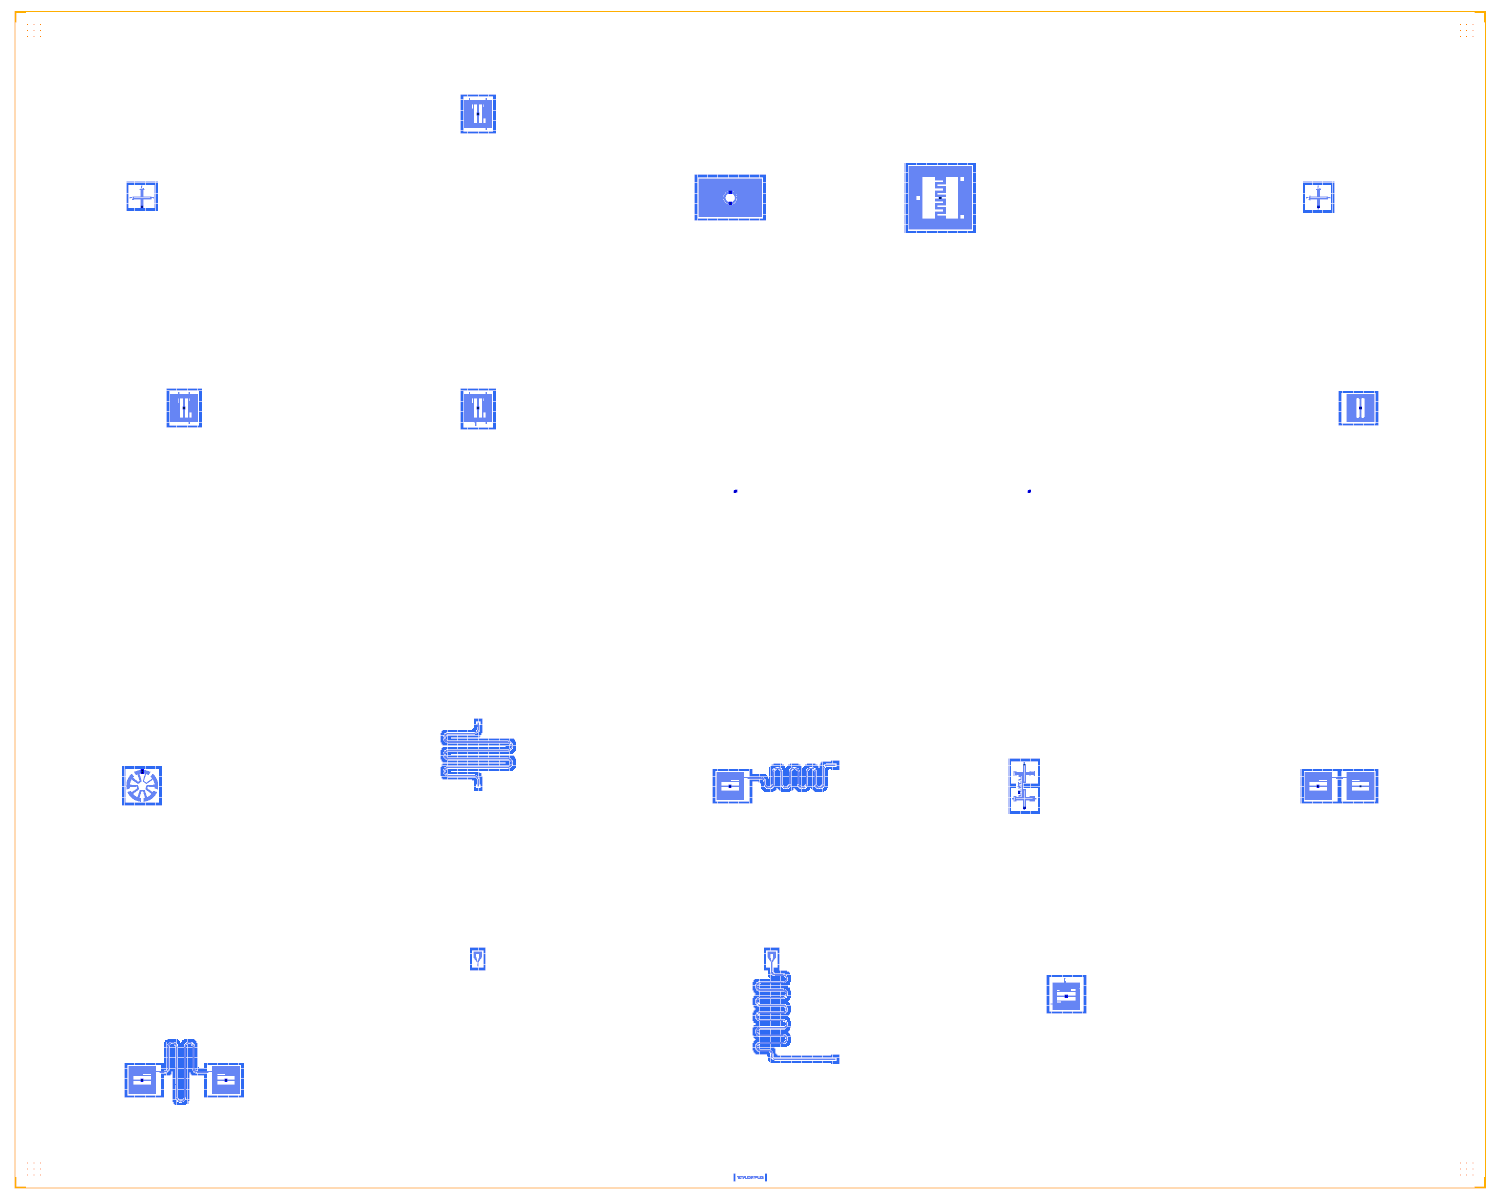

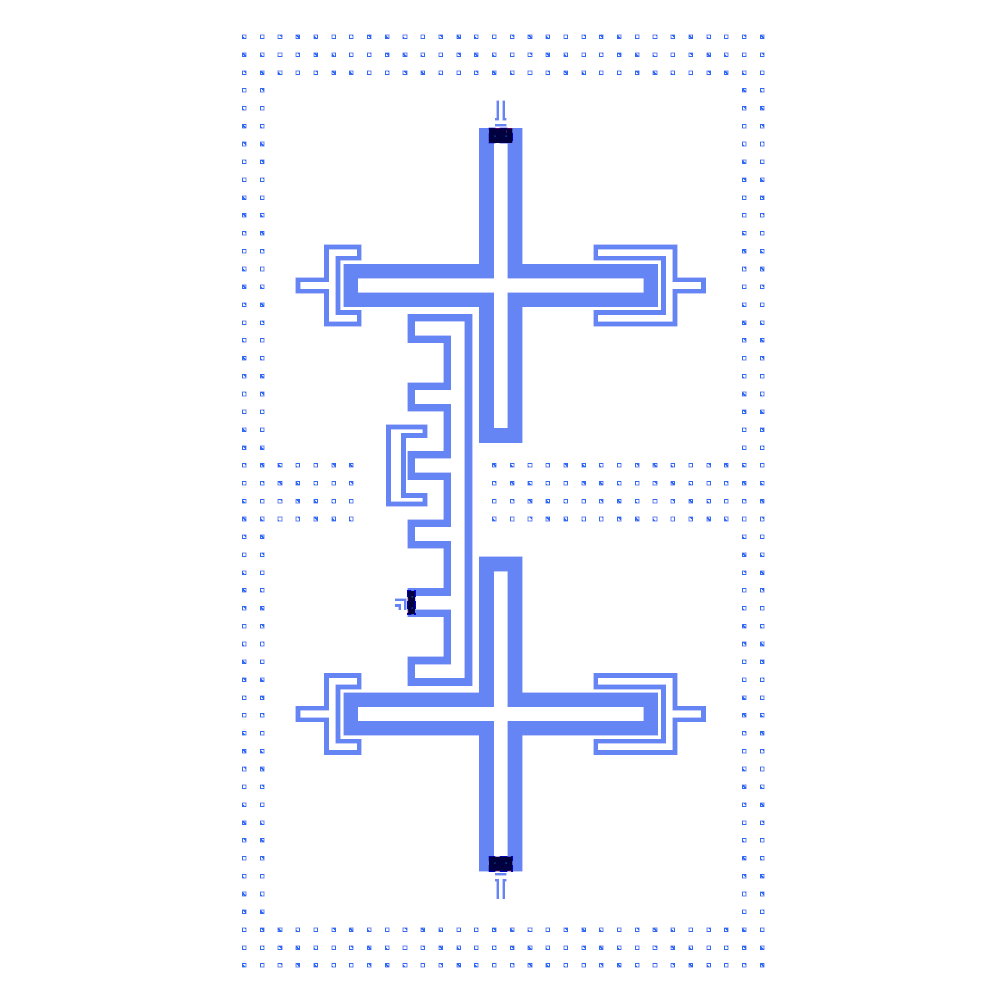

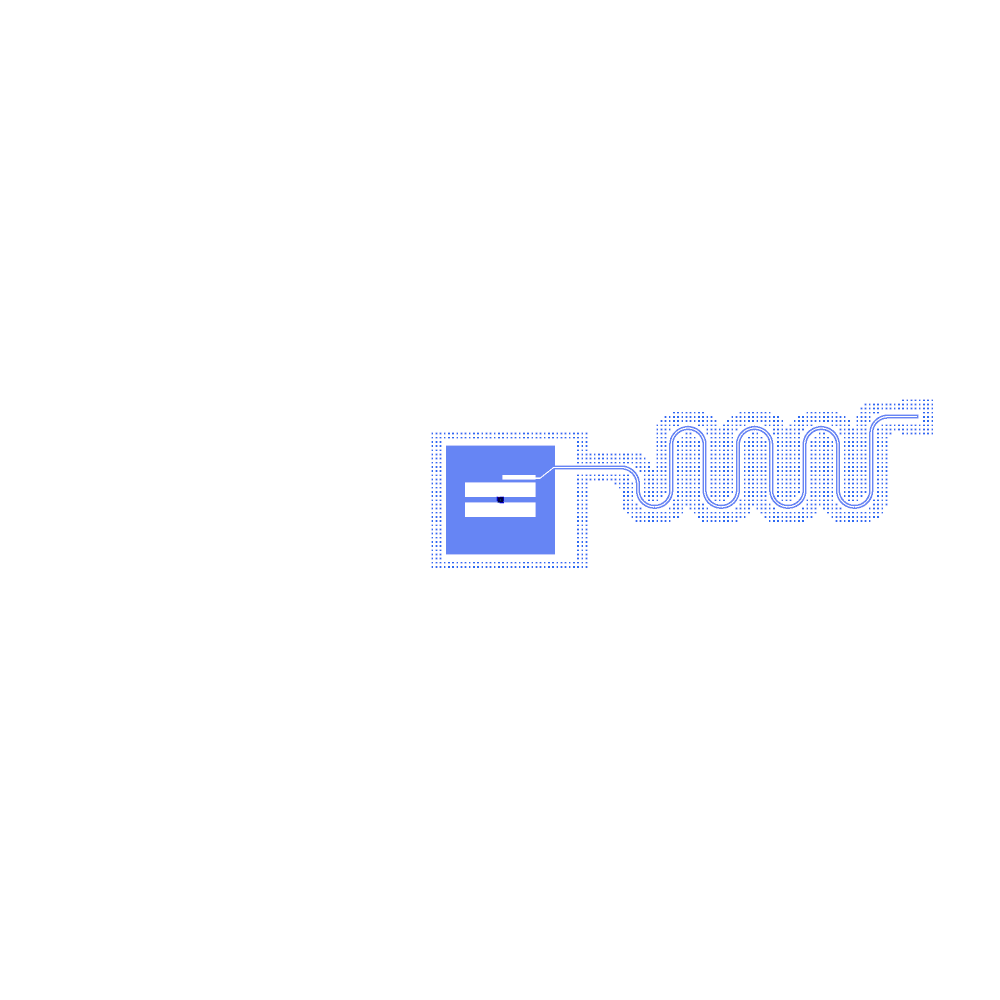

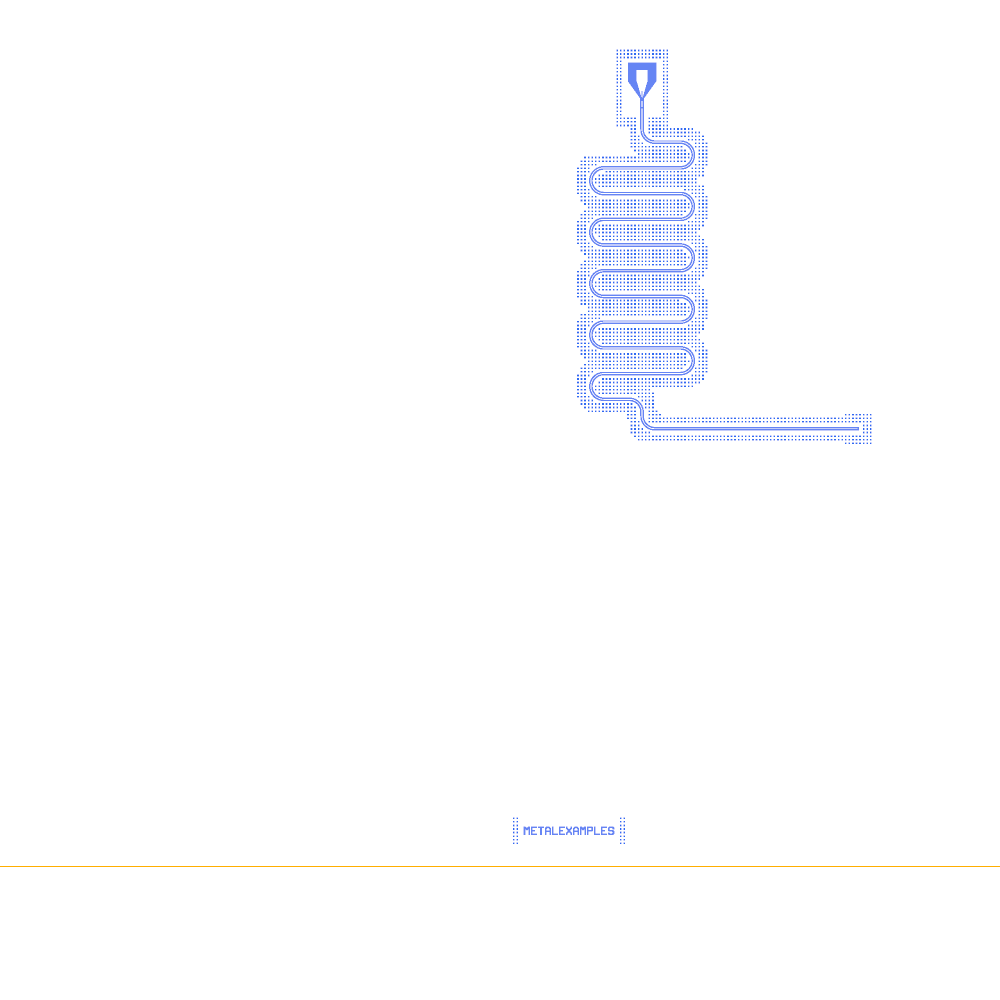

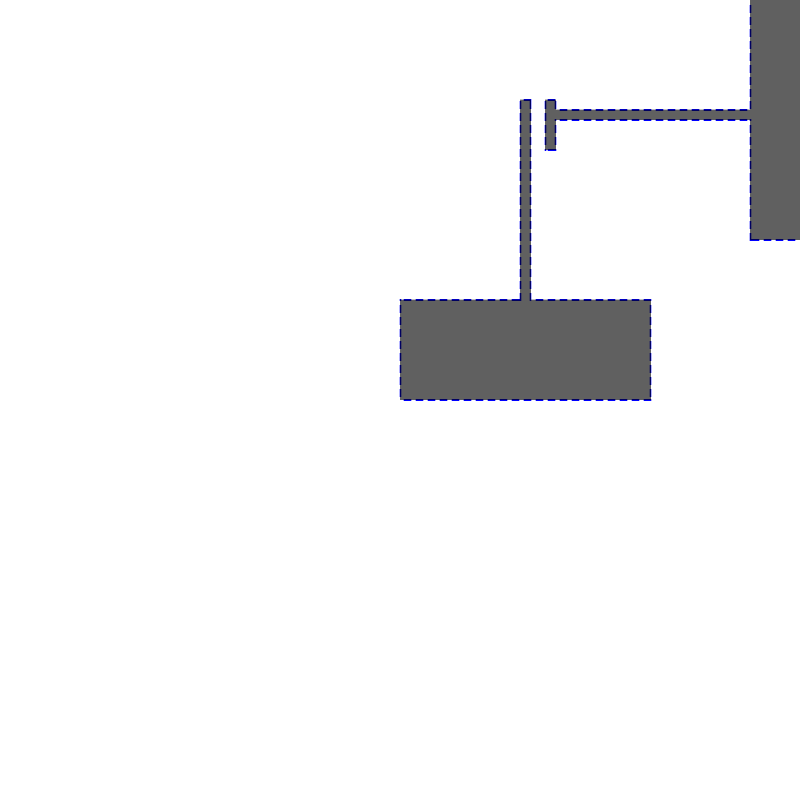

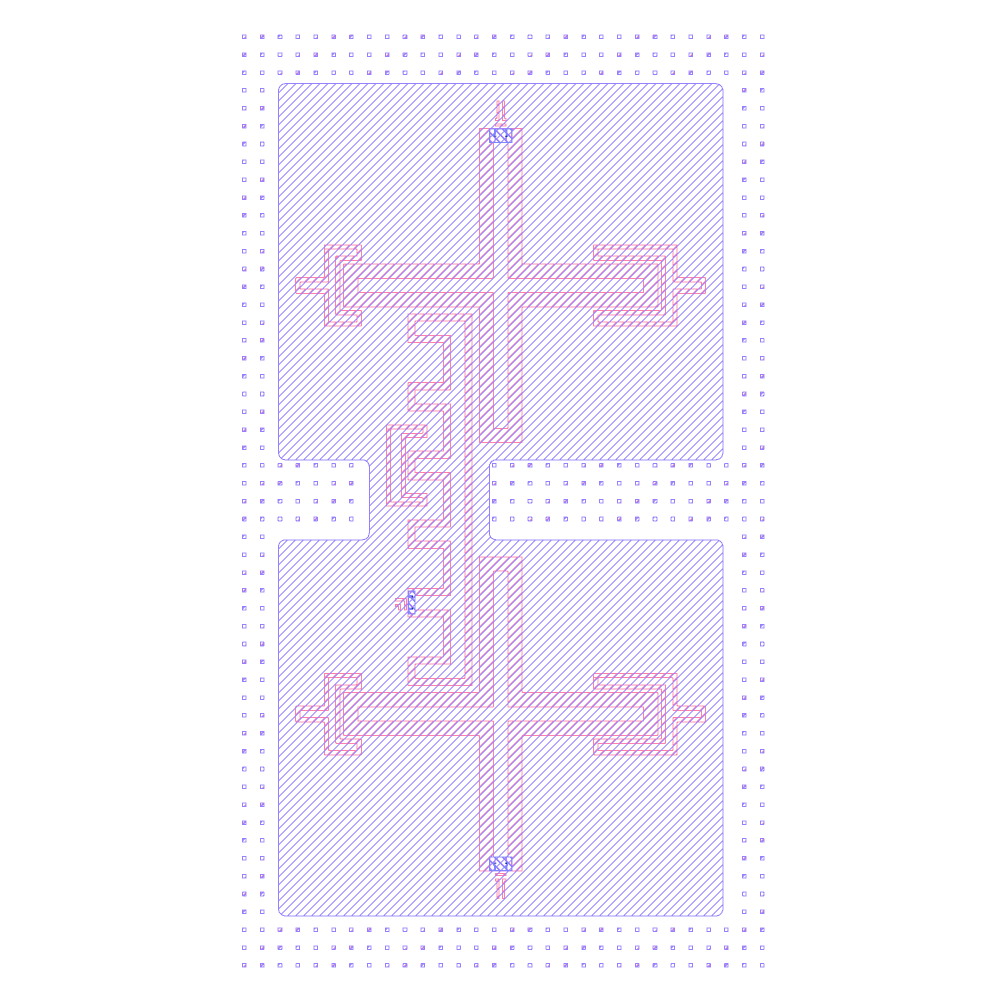

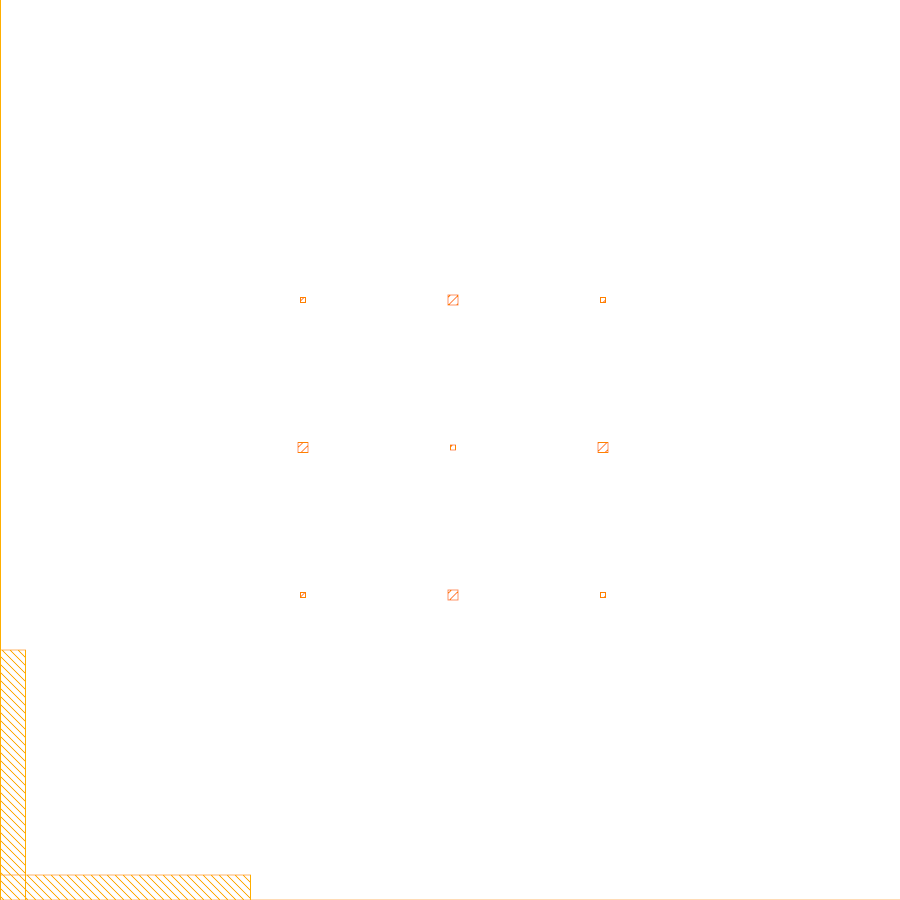

In [18]:
def tile_box(t, half=3500):
    cx, cy = CENTRE[t]
    return (cx - half, cy - half, cx + half, cy + half)


show_snapshot(d, OUT / "component_examples.png", size=(1500, 1200))
show_snapshot(d, OUT / "component_examples_d31.png", box=tile_box("D31", 700), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_c21.png", box=tile_box("C21", 3000), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_e42.png", box=tile_box("E42", 3500), size=(1000, 1000), width=480)
cx, cy = CENTRE["A08"]
show_snapshot(d, OUT / "component_examples_jj.png", box=(cx + 60, cy - 40, cx + 140, cy + 40), size=(800, 800), width=320)
snap_file(Path("build") / "component_examples_fab.oas", OUT / "component_examples_cheese.png",
          box=tile_box("D31", 700), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "component_examples_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every example's components with the options its notebook set, positions and orientations, every route's end pins, Metal corner points and length (B.11 / E.42 meanders at Metal's length on a qcc footprint), the sim groups |
| PDK changes | QCT frame on the 35 × 28 mm board; sapphire stack; trilayer junctions (nominal, SQUIDs, the interdigitated transmon sized for 4.05 GHz); PDK cheese band; the tile grid centred in the die (shift (−478, −936) µm) |
| differs | a catalogue board, not a chip: the E.41 / E.42 launchpads stay in their tiles; the A.08 / A.09 junction tiles keep Metal's drawing; the analysis cells of the examples are not reproduced |
| PDK design warnings | `pad_edge` × 2 (E.41 / E.42, by choice, step 4) |
| open | the D.31 coupler sits above 8 GHz at zero flux; D.32 / D.33 hybridise (identical pockets); the FEM jobs are exported, not solved (`RUN_FEM = False`) |